Enter starting node:5
Enter goal node:1
UCS Traversal: 5 

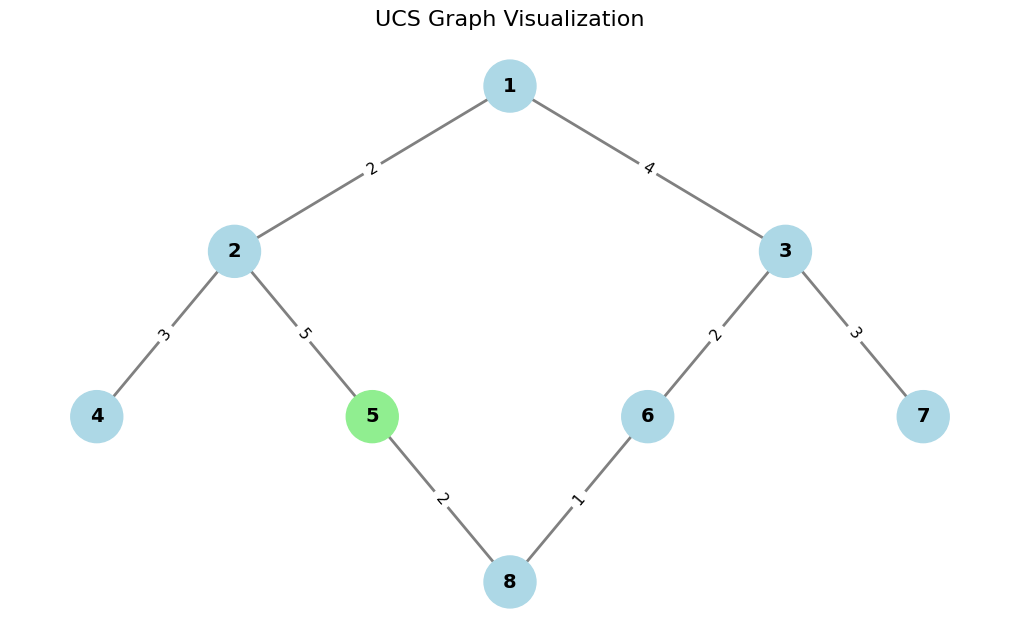

8 

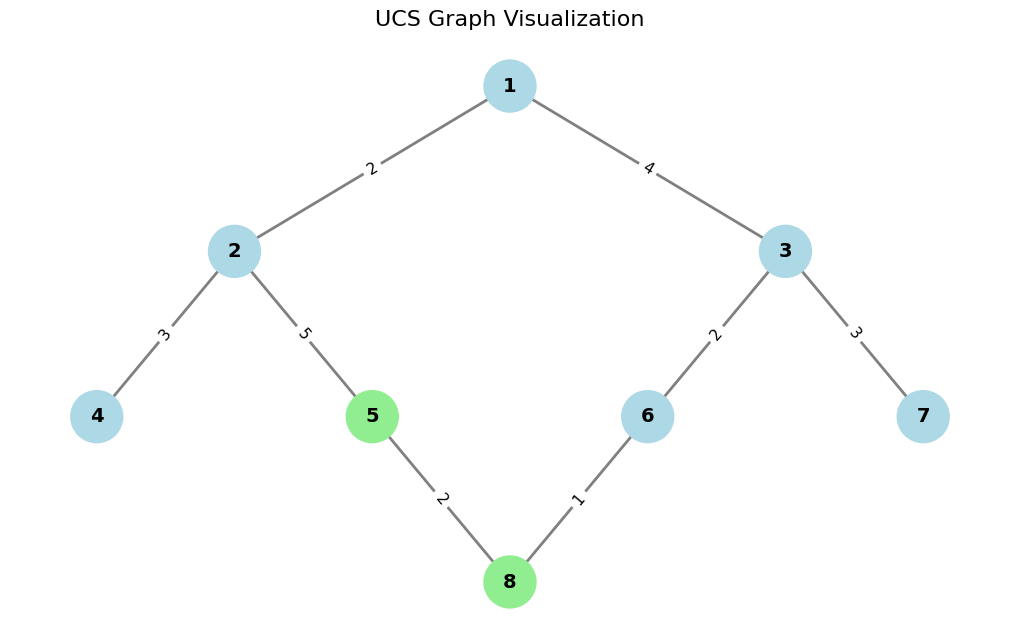

6 

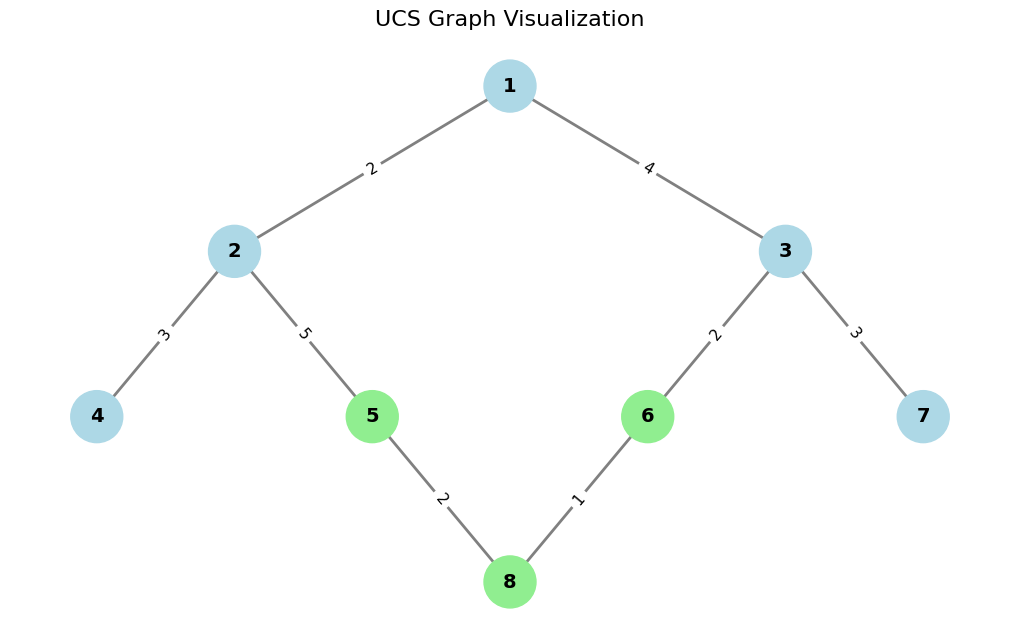

2 

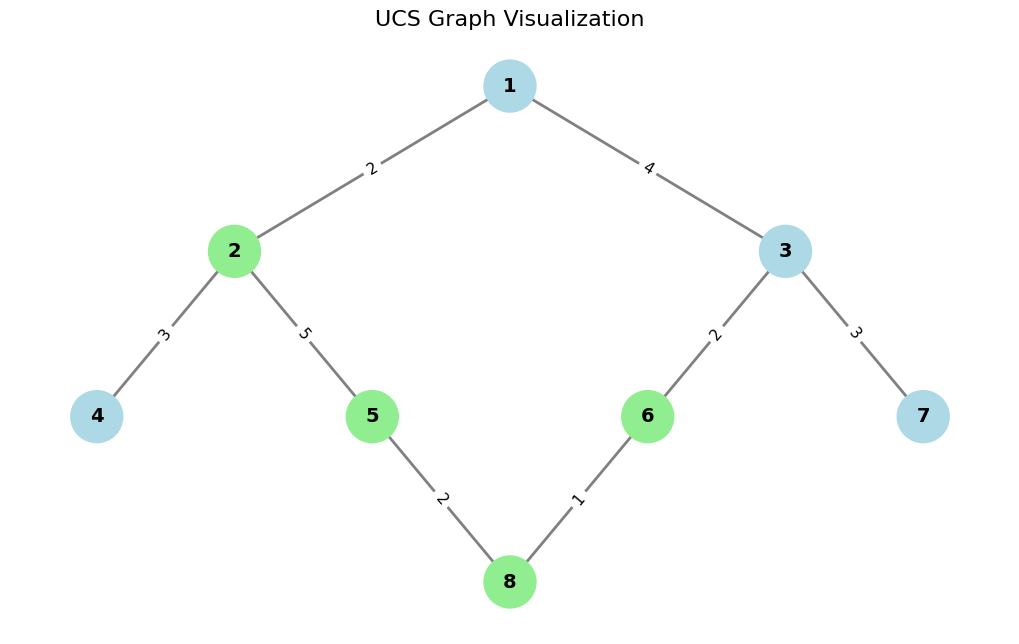

3 

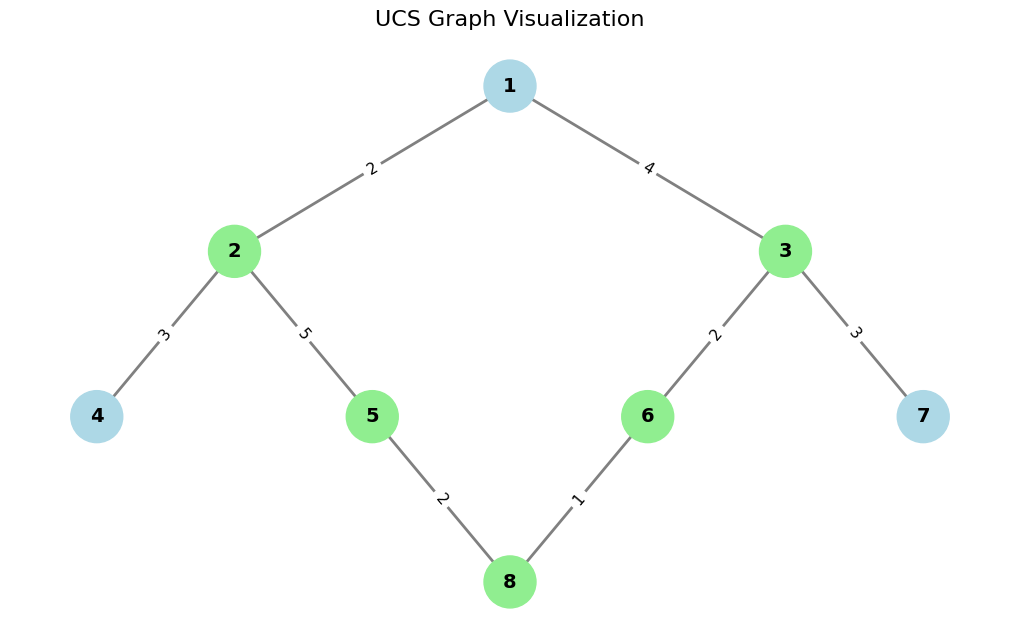

1 

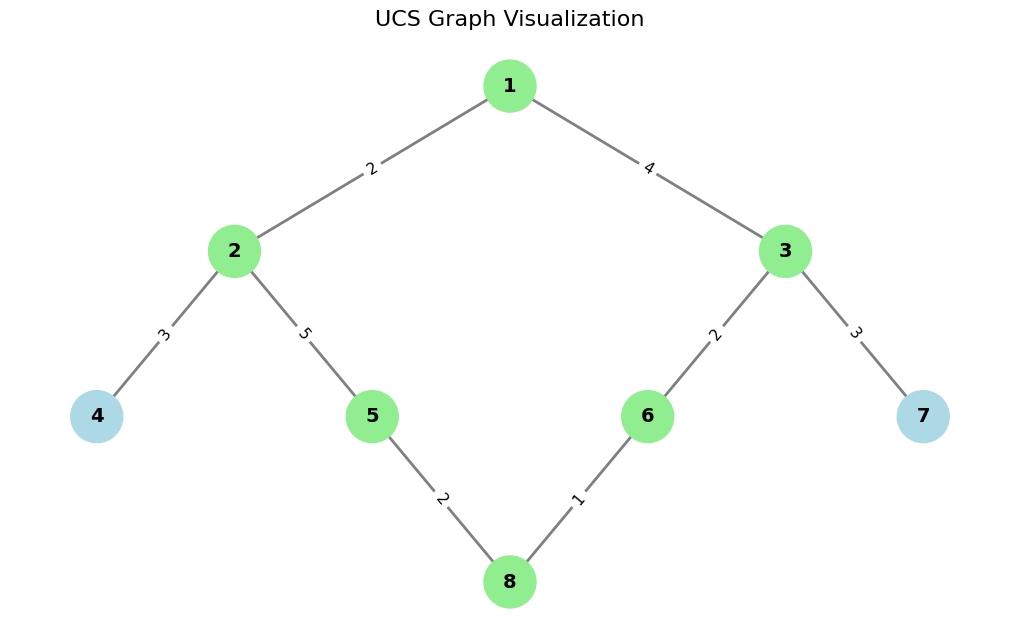


UCS Traversal: [5, 8, 6, 2, 3, 1]
totalcost: 7
Goal found


In [33]:
import networkx as nx
import matplotlib.pyplot as plt
import time
def ucs(start,goal):
  queue=[(0,start,[start])]
  visited=set()
  traversal=[]
  while queue:
    queue.sort(key=lambda x:x[0])
    cost,node,path=queue.pop(0)
    if node in visited:
      continue
    visited.add(node)
    traversal.append(node)
    print(node,end=" ")
    show_graph(visited)
    if node==goal:
      print("\nUCS Traversal:",traversal)
      #print("Shortest path:",path)
      print("totalcost:",cost)
      print("Goal found")
      return
    for neighbour,edge_cost in graph[node]:
      if neighbour not in visited:
        total_cost=cost+edge_cost
        queue.append((total_cost,neighbour,path+[neighbour]))
  print("\ngoal not found")
graph={
    1:[(2,2),(3,4)],
    2:[(1,2),(4,3),(5,5)],
    3:[(1,4),(6,2),(7,3)],
    4:[(2,3)],
    5:[(2,5),(8,2)],
    6:[(3,2),(8,1)],
    7:[(3,3)],
    8:[(5,2),(6,1)]
}
G=nx.Graph()
for node in graph:
  for neighbour,edge_cost in graph[node]:
    G.add_edge(node,neighbour,weight=edge_cost)
pos = {
    1: (0, 3),
    2: (-2, 2),
    3: (2, 2),
    4: (-3, 1),
    5: (-1, 1),
    6: (1, 1),
    7: (3, 1),
    8: (0, 0)
}
def show_graph(visited):
  colors=[]
  for n in G.nodes():
    if n in visited:
      colors.append("lightgreen")
    else:
      colors.append("lightblue")
  plt.figure(figsize=(10,6))
  nx.draw(
      G,pos,with_labels=True,
      node_color=colors,
      node_size=1400,
      font_size=14,
      font_weight="bold",
      edge_color="gray",
      width=2
  )
  edge_labels=nx.get_edge_attributes(G,"weight")

  nx.draw_networkx_edge_labels(
      G,pos,
      edge_labels=edge_labels,
      font_size=11
  )
  plt.title("UCS Graph Visualization",fontsize=16)
  plt.axis("off")
  plt.show()
  time.sleep(1)
start=int(input("Enter starting node:"))
goal=int(input("Enter goal node:"))
print("UCS Traversal:",end=" ")
ucs(start,goal)